In [1]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

import os

project_path = "/content/drive/MyDrive/Plant_Disease_HW2"

print("Main project folders:")
print(os.listdir(project_path))

dataset_path = os.path.join(project_path, "Dataset")

print("\nDataset contents:")
try:
    print(os.listdir(dataset_path))
except Exception as e:
    print("Cannot access dataset:", e)


Main project folders:
['Dataset ', 'splits', 'config', 'models', 'outputs']

Dataset contents:
Cannot access dataset: [Errno 2] No such file or directory: '/content/drive/MyDrive/Plant_Disease_HW2/Dataset'


In [3]:

import json
from pathlib import Path

project_path = Path("/content/drive/MyDrive/Plant_Disease_HW2")

class_names = [
    "Apple___Apple_scab",
    "Apple___Cedar_apple_rust",
    "Apple___healthy",
    "Grape___Black_rot",
    "Grape___healthy",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___healthy",
    "Tomato___Late_blight"
]

class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

NUM_CLASSES = len(class_names)

config_dir = project_path / "config"
config_dir.mkdir(parents=True, exist_ok=True)

with open(config_dir / "class_to_idx.json", "w") as f:
    json.dump(class_to_idx, f, indent=4)

print("Total classes:", NUM_CLASSES)
print(json.dumps(class_to_idx, indent=4))
print("Class mapping saved successfully!")


Total classes: 9
{
    "Apple___Apple_scab": 0,
    "Apple___Cedar_apple_rust": 1,
    "Apple___healthy": 2,
    "Grape___Black_rot": 3,
    "Grape___healthy": 4,
    "Tomato___Bacterial_spot": 5,
    "Tomato___Early_blight": 6,
    "Tomato___healthy": 7,
    "Tomato___Late_blight": 8
}
Class mapping saved successfully!


In [2]:

from google.colab import auth
from googleapiclient.discovery import build

auth.authenticate_user()
service = build("drive", "v3")

folder_id = "1rkAM3SPGkMbStjyfk98fxIFOVB3EFZSK"

results = service.files().list(
    q=f"'{folder_id}' in parents and trashed = false",
    fields="nextPageToken, files(id, name, mimeType)",
    pageSize=100,
    supportsAllDrives=True,
    includeItemsFromAllDrives=True
).execute()

for item in results.get("files", []):
    print(item["name"], "|", item["id"])


PlantDoc_field | 1H9yBx9SqPNyqGqic5kUNIK83GELjYXhT
Plant_Disease_Detection_Dataset | 1N36aAM6a00UOQdzVJGUcfsuptwJN0bg0


In [3]:

# IDs obtained from the previous step
folders = {
    "PlantDoc_field": "1H9yBx9SqPNyqGqic5kUNIK83GELjYXhT",
    "Plant_Disease_Detection_Dataset": "1N36aAM6a00UOQdzVJGUcfsuptwJN0bg0"
}

for folder_name, folder_id in folders.items():
    print(f"\n===== {folder_name} =====")

    page_token = None

    while True:
        response = service.files().list(
            q=f"'{folder_id}' in parents and trashed = false",
            fields="nextPageToken, files(id, name, mimeType)",
            pageSize=100,
            pageToken=page_token,
            supportsAllDrives=True,
            includeItemsFromAllDrives=True
        ).execute()

        for item in response.get("files", []):
            print(item["name"], "|", item["id"])

        page_token = response.get("nextPageToken")
        if not page_token:
            break



===== PlantDoc_field =====
Grapes | 1mv4KkM6rXsYw2iTyNpBlBe-DqEnftMu0
Apple | 1b3zdmGvUIZO6XcXoagw23yv5r6Ufi3kb
Corn | 1AjRwFWSEPn7LDWIlHfE3NdYT6Xo3t9qb
Tomato | 19mpYpMHVYijbS59jin5hRCyj9rMFg3o5

===== Plant_Disease_Detection_Dataset =====
test | 1UsUHFROExGXJbsykAIiPmTbh7lgi1pm6
valid | 1X1u2NWsJSPNZwXJCkqWF5oDdQsDQuCSr
train | 1dDwqIrqojTXj_7gla1ksaGRGd04zn4Y6


In [6]:

# Step 3: Count images for Apple, Grape, and Tomato

# Automatically retrieve the correct folder IDs
dataset_id = folders["Plant_Disease_Detection_Dataset"]

items = list_folder(dataset_id)

TRAIN_ID = next(
    item["id"] for item in items if item["name"].lower() == "train"
)

VALID_ID = next(
    item["id"] for item in items if item["name"].lower() == "valid"
)

# Count images in each class
image_extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

for split_name, split_id in [
    ("TRAIN", TRAIN_ID),
    ("VALID", VALID_ID)
]:
    print(f"\n===== {split_name} =====")

    crops = list_folder(split_id)

    for crop in crops:
        if crop["name"] not in ["Apple", "Grape", "Tomato"]:
            continue

        print(f"\n{crop['name']}:")

        disease_folders = list_folder(crop["id"])

        for disease in disease_folders:
            if disease["mimeType"] != "application/vnd.google-apps.folder":
                continue

            images = list_folder(disease["id"])

            image_count = sum(
                item["name"].lower().endswith(image_extensions)
                for item in images
            )

            print(f"  {disease['name']}: {image_count} images")

print("\nImage counting completed!")



===== TRAIN =====

Grape:
  Black Rot: 1889 images
  Healthy: 1692 images

Apple:
  Apple Scab: 2016 images
  Healthy: 2008 images
  Cedar Apple Rust: 1760 images

Tomato:
  Healthy: 1926 images
  Bacterial Spot: 1702 images
  Early Blight: 1920 images
  Late Blight: 1853 images

===== VALID =====

Grape:
  Black Rot: 472 images
  Healthy: 423 images

Tomato:
  Early Blight: 480 images
  Bacterial Spot: 425 images
  Healthy: 481 images
  Late Blight: 463 images

Apple:
  Cedar Apple Rust: 440 images
  Apple Scab: 504 images
  Healthy: 502 images

Image counting completed!


In [5]:

# Retrieve the correct Train and Valid folder IDs

dataset_id = folders["Plant_Disease_Detection_Dataset"]

items = list_folder(dataset_id)

for item in items:
    print(item["name"], ":", item["id"])

    if item["name"].lower() == "train":
        TRAIN_ID = item["id"]

    elif item["name"].lower() == "valid":
        VALID_ID = item["id"]

print("\nTRAIN_ID:", TRAIN_ID)
print("VALID_ID:", VALID_ID)


test : 1UsUHFROExGXJbsykAIiPmTbh7lgi1pm6
valid : 1X1u2NWsJSPNZwXJCkqWF5oDdQsDQuCSr
train : 1dDwqIrqojTXj_7gla1ksaGRGd04zn4Y6

TRAIN_ID: 1dDwqIrqojTXj_7gla1ksaGRGd04zn4Y6
VALID_ID: 1X1u2NWsJSPNZwXJCkqWF5oDdQsDQuCSr


In [10]:

import pandas as pd
from pathlib import Path

# Our 9 classes
folder_to_class = {
    ("Apple", "Apple Scab"): "Apple___Apple_scab",
    ("Apple", "Cedar Apple Rust"): "Apple___Cedar_apple_rust",
    ("Apple", "Healthy"): "Apple___healthy",
    ("Grape", "Black Rot"): "Grape___Black_rot",
    ("Grape", "Healthy"): "Grape___healthy",
    ("Tomato", "Bacterial Spot"): "Tomato___Bacterial_spot",
    ("Tomato", "Early Blight"): "Tomato___Early_blight",
    ("Tomato", "Healthy"): "Tomato___healthy",
    ("Tomato", "Late Blight"): "Tomato___Late_blight"
}

image_extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

def create_manifest(split_id):
    records = []

    for crop in list_folder(split_id):
        if crop["name"] not in ["Apple", "Grape", "Tomato"]:
            continue

        for disease in list_folder(crop["id"]):
            key = (crop["name"], disease["name"])

            if key not in folder_to_class:
                raise ValueError(f"Unexpected class: {key}")

            class_name = folder_to_class[key]

            for image in list_folder(disease["id"]):
                if image["name"].lower().endswith(image_extensions):
                    records.append({
                        "file_id": image["id"],
                        "filename": image["name"],
                        "class_name": class_name,
                        "label": class_to_idx[class_name]
                    })

    return pd.DataFrame(records)

# Generate CSV manifests
train_df = create_manifest(TRAIN_ID)
valid_df = create_manifest(VALID_ID)

# Verify image IDs do not overlap
overlap = set(train_df["file_id"]) & set(valid_df["file_id"])

print("Training images:", len(train_df))
print("Validation images:", len(valid_df))
print("Overlapping file IDs:", len(overlap))

# Save the CSV files
if overlap:
    raise ValueError("Overlapping file IDs found!")

splits_dir = Path(project_path) / "splits"
splits_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(splits_dir / "train.csv", index=False)
valid_df.to_csv(splits_dir / "valid.csv", index=False)

print("\nCSV files saved successfully!")
print("\nTraining distribution:")
print(train_df["class_name"].value_counts().sort_index())

print("\nValidation distribution:")
print(valid_df["class_name"].value_counts().sort_index())


Training images: 16766
Validation images: 4190
Overlapping file IDs: 0

CSV files saved successfully!

Training distribution:
class_name
Apple___Apple_scab          2016
Apple___Cedar_apple_rust    1760
Apple___healthy             2008
Grape___Black_rot           1889
Grape___healthy             1692
Tomato___Bacterial_spot     1702
Tomato___Early_blight       1920
Tomato___Late_blight        1853
Tomato___healthy            1926
Name: count, dtype: int64

Validation distribution:
class_name
Apple___Apple_scab          504
Apple___Cedar_apple_rust    440
Apple___healthy             502
Grape___Black_rot           472
Grape___healthy             423
Tomato___Bacterial_spot     425
Tomato___Early_blight       480
Tomato___Late_blight        463
Tomato___healthy            481
Name: count, dtype: int64


In [9]:

import json
from pathlib import Path

# Project folder
project_path = Path("/content/drive/MyDrive/Plant_Disease_HW2")
config_dir = project_path / "config"
config_dir.mkdir(parents=True, exist_ok=True)

# Define the 9 classes
class_names = [
    "Apple___Apple_scab",
    "Apple___Cedar_apple_rust",
    "Apple___healthy",
    "Grape___Black_rot",
    "Grape___healthy",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___healthy",
    "Tomato___Late_blight"
]

class_to_idx = {
    name: i for i, name in enumerate(class_names)
}

NUM_CLASSES = len(class_names)

# Save class mapping
mapping_path = config_dir / "class_to_idx.json"

with open(mapping_path, "w") as f:
    json.dump(class_to_idx, f, indent=4)

print("Class mapping saved successfully!")
print("Total classes:", NUM_CLASSES)
print("File exists:", mapping_path.exists())


Class mapping saved successfully!
Total classes: 9
File exists: True


Class: Grape___Black_rot
Filename: 89db9e1c-2cb5-4ccd-b50a-f78dc007c380___FAM_B.Rot 3043_flipLR.JPG
Image size: (256, 256)
Image loaded successfully!


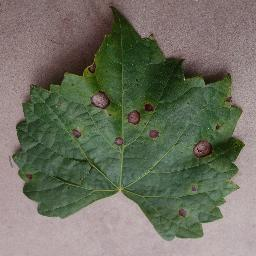

In [11]:

from googleapiclient.http import MediaIoBaseDownload
from PIL import Image
from IPython.display import display
import io

# Select one training image
sample = train_df.iloc[0]

print("Class:", sample["class_name"])
print("Filename:", sample["filename"])

# Download image from Google Drive
request = service.files().get_media(
    fileId=sample["file_id"],
    supportsAllDrives=True
)

image_data = io.BytesIO()
downloader = MediaIoBaseDownload(image_data, request)

done = False
while not done:
    status, done = downloader.next_chunk()

# Open and display the image
image_data.seek(0)
image = Image.open(image_data).convert("RGB")

print("Image size:", image.size)
print("Image loaded successfully!")

display(image)


In [12]:

from pathlib import Path
import json

# Shared project configuration
PROJECT_NAME = "Plant_Disease_HW2"
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32

# Google Drive location
DRIVE_ROOT = Path("/content/drive/MyDrive")
PROJECT_ROOT = DRIVE_ROOT / PROJECT_NAME

# Local Colab storage for images
DATA_ROOT = Path("/content/plant_disease_data")

TRAIN_DIR = DATA_ROOT / "train"
VALID_DIR = DATA_ROOT / "valid"
TEST_DIR = DATA_ROOT / "plantdoc_test"

# Project output folders
SPLITS_DIR = PROJECT_ROOT / "splits"
CONFIG_DIR = PROJECT_ROOT / "config"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"

# Create directories
for folder in [
    TRAIN_DIR, VALID_DIR, TEST_DIR,
    SPLITS_DIR, CONFIG_DIR,
    MODELS_DIR, OUTPUTS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# Configuration to share with C2
config = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "num_classes": 9,
    "crops": ["Apple", "Grape", "Tomato"],
    "normalization": "ImageNet",
    "train_fraction": 0.8,
    "validation_fraction": 0.2,
    "test_dataset": "PlantDoc"
}

with open(CONFIG_DIR / "project_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Project configuration saved!")
print("Training folder:", TRAIN_DIR)
print("Validation folder:", VALID_DIR)
print("Testing folder:", TEST_DIR)


Project configuration saved!
Training folder: /content/plant_disease_data/train
Validation folder: /content/plant_disease_data/valid
Testing folder: /content/plant_disease_data/plantdoc_test


In [13]:

from googleapiclient.http import MediaIoBaseDownload
from pathlib import Path
import io

def download_image(file_id, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.exists() and destination.stat().st_size > 0:
        return

    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True
    )

    with open(destination, "wb") as f:
        downloader = MediaIoBaseDownload(f, request)
        done = False

        while not done:
            _, done = downloader.next_chunk()

# Test download with 5 images
for _, row in train_df.head(5).iterrows():
    destination = TRAIN_DIR / row["class_name"] / (
        str(row["file_id"]) + Path(row["filename"]).suffix
    )

    download_image(row["file_id"], destination)
    print("Downloaded:", destination.name)

print("\nTest download completed!")


Downloaded: 1-Z6URButyoGoQzF1hewm6rZXGK0iKc6i.JPG
Downloaded: 1Vklh-9fiVhsMqVgilkHqi63lfFjW7GAs.JPG
Downloaded: 1yQ6x4kSXioKjIS-os14hIL-7Kd5D7K4q.JPG
Downloaded: 1YA4ZXLDdXwylT6WFQnrFIT8yVQ78whLn.JPG
Downloaded: 1xOWPSWeOGBPUZJz6qCTfkGCmthdC1_NJ.JPG

Test download completed!


In [14]:

from PIL import Image

verified = 0

for image_path in TRAIN_DIR.rglob("*"):
    if not image_path.is_file():
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()
        verified += 1
    except Exception as e:
        print("Invalid image:", image_path.name, e)

print("Verified images:", verified)
print("Image verification completed!")


Verified images: 5
Image verification completed!


In [16]:

from pathlib import Path
from googleapiclient.http import MediaIoBaseDownload
from googleapiclient.errors import HttpError
from tqdm.auto import tqdm
import time
import random

# Permanent Google Drive storage
PREPARED_ROOT = Path(
    "/content/drive/MyDrive/Plant_Disease_HW2/prepared_data"
)

def download_dataset(df, split_name, limit=None):
    split_dir = PREPARED_ROOT / split_name
    split_dir.mkdir(parents=True, exist_ok=True)

    records = df if limit is None else df.head(limit)
    downloaded = 0
    skipped = 0
    failed = []

    for row in tqdm(
        records.itertuples(index=False),
        total=len(records),
        desc=split_name
    ):
        extension = Path(row.filename).suffix.lower()
        destination = (
            split_dir / row.class_name /
            f"{row.file_id}{extension}"
        )
        destination.parent.mkdir(parents=True, exist_ok=True)

        if destination.exists() and destination.stat().st_size > 0:
            skipped += 1
            continue

        temp_path = destination.with_name(destination.name + ".part")

        for attempt in range(5):
            try:
                request = service.files().get_media(
                    fileId=row.file_id,
                    supportsAllDrives=True
                )

                with open(temp_path, "wb") as file:
                    downloader = MediaIoBaseDownload(file, request)
                    done = False
                    while not done:
                        _, done = downloader.next_chunk()

                temp_path.replace(destination)
                downloaded += 1
                break

            except (HttpError, OSError) as e:
                temp_path.unlink(missing_ok=True)

                if attempt == 4:
                    failed.append((row.file_id, str(e)))
                else:
                    time.sleep(min(60, 2 ** attempt + random.random()))

    print(f"\n{split_name} completed:")
    print("Downloaded:", downloaded)
    print("Already present:", skipped)
    print("Failed:", len(failed))

    return failed

# First test: 50 images from each dataset
train_failures = download_dataset(train_df, "train")
valid_failures = download_dataset(valid_df, "valid")


train:   0%|          | 0/16766 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [21]:

# Download images in batches of 1,000

BATCH_SIZE_DOWNLOAD = 1000
batch_number =5  # Change this to 2, 3, etc.

# Combine training and validation records
train_batches = [
    ("train", train_df),
    ("valid", valid_df)
]

# Build the complete download list
import pandas as pd

all_images = pd.concat([
    train_df.assign(split="train"),
    valid_df.assign(split="valid")
], ignore_index=True)

total_batches = (
    len(all_images) + BATCH_SIZE_DOWNLOAD - 1
) // BATCH_SIZE_DOWNLOAD

start = (batch_number - 1) * BATCH_SIZE_DOWNLOAD
end = min(start + BATCH_SIZE_DOWNLOAD, len(all_images))

batch = all_images.iloc[start:end]

print(f"Batch {batch_number} of {total_batches}")
print(f"Images in batch: {len(batch)}")

# Download each split separately
batch_train = batch[batch["split"] == "train"]
batch_valid = batch[batch["split"] == "valid"]

train_failures = download_dataset(batch_train, "train")
valid_failures = download_dataset(batch_valid, "valid")

print("\nBatch completed!")
print("Failed downloads:", len(train_failures) + len(valid_failures))


Batch 5 of 21
Images in batch: 1000


train:   0%|          | 0/1000 [00:00<?, ?it/s]


train completed:
Downloaded: 1000
Already present: 0
Failed: 0


valid: 0it [00:00, ?it/s]


valid completed:
Downloaded: 0
Already present: 0
Failed: 0

Batch completed!
Failed downloads: 0


In [22]:

# STEP 8: PARALLEL DATASET DOWNLOADING
# Resume after Batch 5 (first 5,000 images completed)

import pandas as pd
import time
import random
import threading
import google.auth

from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from tqdm.auto import tqdm
from PIL import Image

# ========================================
# 1. CONFIGURATION
# ========================================

MAX_WORKERS = 4
START_INDEX = 5000

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Plant_Disease_HW2"
)

PREPARED_ROOT = PROJECT_ROOT / "prepared_data"

# Load saved manifests from Google Drive.
# This keeps the download order consistent.

train_csv = PROJECT_ROOT / "splits" / "train.csv"
valid_csv = PROJECT_ROOT / "splits" / "valid.csv"

train_data = pd.read_csv(train_csv)
valid_data = pd.read_csv(valid_csv)

all_images = pd.concat([
    train_data.assign(split="train"),
    valid_data.assign(split="valid")
], ignore_index=True)

remaining = all_images.iloc[START_INDEX:].copy()

print("Total dataset images:", len(all_images))
print("Images remaining in download schedule:", len(remaining))
print("Parallel workers:", MAX_WORKERS)

# ========================================
# 2. GOOGLE DRIVE AUTHENTICATION
# ========================================

from google.colab import auth

auth.authenticate_user()
credentials, _ = google.auth.default()

# Give each worker thread its own API client.
thread_local = threading.local()

def get_drive_service():
    if not hasattr(thread_local, "service"):
        thread_local.service = build(
            "drive",
            "v3",
            credentials=credentials,
            cache_discovery=False
        )
    return thread_local.service

# ========================================
# 3. DOWNLOAD FUNCTION
# ========================================

def download_one(row):

    extension = Path(row["filename"]).suffix.lower()

    destination = (
        PREPARED_ROOT
        / row["split"]
        / row["class_name"]
        / f'{row["file_id"]}{extension}'
    )

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # Skip previously downloaded valid images.
    if destination.exists() and destination.stat().st_size > 0:
        try:
            with Image.open(destination) as img:
                img.verify()
            return "skipped"
        except Exception:
            destination.unlink(missing_ok=True)

    temp_path = destination.with_name(
        destination.name + ".part"
    )

    for attempt in range(5):

        try:
            service_worker = get_drive_service()

            request = service_worker.files().get_media(
                fileId=row["file_id"],
                supportsAllDrives=True
            )

            with open(temp_path, "wb") as file:
                downloader = MediaIoBaseDownload(
                    file,
                    request,
                    chunksize=1024 * 1024
                )

                done = False

                while not done:
                    _, done = downloader.next_chunk()

            # Verify image before saving permanently.
            with Image.open(temp_path) as img:
                img.verify()

            temp_path.replace(destination)

            return "downloaded"

        except Exception:
            temp_path.unlink(missing_ok=True)

            if attempt < 4:
                time.sleep(
                    min(60, 2 ** attempt + random.random())
                )

    return "failed"

# ========================================
# 4. DOWNLOAD REMAINING IMAGES
# ========================================

records = remaining.to_dict("records")

results = {
    "downloaded": 0,
    "skipped": 0,
    "failed": 0
}

failed_ids = []

with ThreadPoolExecutor(
    max_workers=MAX_WORKERS
) as executor:

    futures = {
        executor.submit(download_one, row): row
        for row in records
    }

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Parallel downloading"
    ):

        row = futures[future]

        try:
            status = future.result()
        except Exception:
            status = "failed"

        results[status] += 1

        if status == "failed":
            failed_ids.append(row["file_id"])

# ========================================
# 5. FINAL RESULTS
# ========================================

print("\n===== DOWNLOAD RESULTS =====")

print("Newly downloaded:", results["downloaded"])
print("Already present:", results["skipped"])
print("Failed:", results["failed"])

# Save failure list for retrying.
if failed_ids:
    failure_path = PROJECT_ROOT / "outputs" / "failed_download_ids.csv"

    pd.DataFrame({
        "file_id": failed_ids
    }).to_csv(failure_path, index=False)

    print("Failure list saved:", failure_path)

print("\nParallel download run completed!")


Total dataset images: 20956
Images remaining in download schedule: 15956
Parallel workers: 4


Parallel downloading:   0%|          | 0/15956 [00:00<?, ?it/s]


===== DOWNLOAD RESULTS =====
Newly downloaded: 15906
Already present: 50
Failed: 0

Parallel download run completed!


In [23]:

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

root = Path(
    "/content/drive/MyDrive/Plant_Disease_HW2/prepared_data"
)

expected = {
    "train": 16766,
    "valid": 4190
}

for split, expected_count in expected.items():
    folder = root / split

    files = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower()
        in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]

    invalid = []

    for path in tqdm(files, desc=f"Verifying {split}"):
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            invalid.append(str(path))

    print(f"\n{split.upper()}")
    print("Expected:", expected_count)
    print("Found:", len(files))
    print("Invalid:", len(invalid))
    print("Count matches:", len(files) == expected_count)

    if invalid:
        print("Invalid files:", invalid[:10])


Verifying train:   0%|          | 0/16766 [00:00<?, ?it/s]


TRAIN
Expected: 16766
Found: 16766
Invalid: 0
Count matches: True


Verifying valid:   0%|          | 0/4190 [00:00<?, ?it/s]


VALID
Expected: 4190
Found: 4190
Invalid: 0
Count matches: True


In [25]:

# STEP 9: IMAGE PREPROCESSING & AUGMENTATION

import torch
from torchvision import transforms
from PIL import Image
from pathlib import Path

# ========================================
# 1. CONFIGURATION
# ========================================

IMAGE_SIZE = 224

PREPARED_ROOT = Path(
    "/content/drive/MyDrive/Plant_Disease_HW2/prepared_data"
)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# ========================================
# 2. TRAINING PREPROCESSING
# ========================================

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# ========================================
# 3. VALIDATION & TEST PREPROCESSING
# ========================================

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# ========================================
# 4. FIND A SAMPLE IMAGE
# ========================================

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

train_folder = PREPARED_ROOT / "train"

sample_path = next(
    (
        p for p in train_folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    ),
    None
)

if sample_path is None:
    raise FileNotFoundError(
        "No training images found in prepared_data/train"
    )

print("Sample image:", sample_path.name)

# ========================================
# 5. TEST BOTH TRANSFORMS
# ========================================

with Image.open(sample_path) as img:
    image = img.convert("RGB")

    train_tensor = train_transform(image)
    eval_tensor = eval_transform(image)

print("\nTraining tensor:", train_tensor.shape)
print("Validation tensor:", eval_tensor.shape)

assert train_tensor.shape == (3, 224, 224)
assert eval_tensor.shape == (3, 224, 224)

print("\nPreprocessing and augmentation test passed!")


Sample image: 17lGNJv4z-X4rwzJJopltFtHhLj0MJ8UC.jpg

Training tensor: torch.Size([3, 224, 224])
Validation tensor: torch.Size([3, 224, 224])

Preprocessing and augmentation test passed!


In [26]:

# STEP 10: CALCULATE CLASS WEIGHTS

import torch
import pandas as pd
import json
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2")

# Load saved training manifest and class mapping
train_df = pd.read_csv(PROJECT_ROOT / "splits" / "train.csv")

with open(PROJECT_ROOT / "config" / "class_to_idx.json") as f:
    class_to_idx = json.load(f)

# Use training data only
num_classes = len(class_to_idx)
counts = (
    train_df["label"]
    .value_counts()
    .reindex(range(num_classes), fill_value=0)
    .sort_index()
)

if (counts == 0).any():
    raise ValueError("One or more classes have no training images.")

# Balanced class weight formula: N / (K * class_count)
weights = len(train_df) / (num_classes * counts.to_numpy())

class_weights = torch.tensor(weights, dtype=torch.float32)

# Save weights for C2
torch.save(
    class_weights,
    PROJECT_ROOT / "config" / "class_weights.pt"
)

print("Training image counts and class weights:\n")

for class_name, idx in sorted(class_to_idx.items(), key=lambda x: x[1]):
    print(
        f"{idx}: {class_name} | "
        f"Images: {counts[idx]} | "
        f"Weight: {class_weights[idx]:.4f}"
    )

print("\nClass weights saved successfully!")


Training image counts and class weights:

0: Apple___Apple_scab | Images: 2016 | Weight: 0.9241
1: Apple___Cedar_apple_rust | Images: 1760 | Weight: 1.0585
2: Apple___healthy | Images: 2008 | Weight: 0.9277
3: Grape___Black_rot | Images: 1889 | Weight: 0.9862
4: Grape___healthy | Images: 1692 | Weight: 1.1010
5: Tomato___Bacterial_spot | Images: 1702 | Weight: 1.0945
6: Tomato___Early_blight | Images: 1920 | Weight: 0.9703
7: Tomato___healthy | Images: 1926 | Weight: 0.9672
8: Tomato___Late_blight | Images: 1853 | Weight: 1.0053

Class weights saved successfully!


In [27]:

# STEP 11: CREATE TRAINING AND VALIDATION DATALOADERS

import json
import pandas as pd
import torch

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader

PROJECT_ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2")
DATA_ROOT = PROJECT_ROOT / "prepared_data"

# Load saved manifests and class mapping
train_df = pd.read_csv(PROJECT_ROOT / "splits" / "train.csv")
valid_df = pd.read_csv(PROJECT_ROOT / "splits" / "valid.csv")

with open(PROJECT_ROOT / "config" / "class_to_idx.json") as f:
    class_to_idx = json.load(f)

class PlantDiseaseDataset(Dataset):
    def __init__(self, dataframe, split, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.split = split
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        extension = Path(row["filename"]).suffix.lower()

        image_path = (
            DATA_ROOT / self.split / row["class_name"]
            / f'{row["file_id"]}{extension}'
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = int(row["label"])

        return image, label

# Create datasets
train_dataset = PlantDiseaseDataset(
    train_df, "train", transform=train_transform
)

valid_dataset = PlantDiseaseDataset(
    valid_df, "valid", transform=eval_transform
)

# Use 0 workers initially for reliable Google Drive access
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# Verify one batch
train_images, train_labels = next(iter(train_loader))
valid_images, valid_labels = next(iter(valid_loader))

print("Training samples:", len(train_dataset))
print("Validation samples:", len(valid_dataset))
print("Training batch shape:", train_images.shape)
print("Validation batch shape:", valid_images.shape)
print("Training labels:", train_labels[:10].tolist())
print("Validation labels:", valid_labels[:10].tolist())

assert train_images.shape == (32, 3, 224, 224)
assert valid_images.shape == (32, 3, 224, 224)
assert train_labels.min() >= 0 and train_labels.max() < 9

print("\nDataLoader test passed!")


Training samples: 16766
Validation samples: 4190
Training batch shape: torch.Size([32, 3, 224, 224])
Validation batch shape: torch.Size([32, 3, 224, 224])
Training labels: [7, 5, 0, 1, 7, 7, 2, 1, 1, 3]
Validation labels: [3, 3, 3, 3, 3, 3, 3, 3, 3, 3]

DataLoader test passed!


In [28]:

# STEP 12: PLANTDOC DATASET INSPECTION & TEST CSV

import pandas as pd
import json
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2")

# Load the existing class mapping
with open(PROJECT_ROOT / "config" / "class_to_idx.json") as f:
    class_to_idx = json.load(f)

# Retrieve PlantDoc folder ID from the verified parent
plantdoc_id = folders["PlantDoc_field"]

# Standardize folder names to match our 9 classes
plantdoc_mapping = {
    ("Apple", "Apple Scab"): "Apple___Apple_scab",
    ("Apple", "Cedar Apple Rust"): "Apple___Cedar_apple_rust",
    ("Apple", "Healthy"): "Apple___healthy",

    ("Grapes", "Grape___Black_rot"): "Grape___Black_rot",
    ("Grapes", "Grape___healthy"): "Grape___healthy",

    ("Tomato", "Bacterial Spot"): "Tomato___Bacterial_spot",
    ("Tomato", "Early Blight"): "Tomato___Early_blight",
    ("Tomato", "Healthy"): "Tomato___healthy",
    ("Tomato", "Late Blight"): "Tomato___Late_blight"
}

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
records = []

for crop in list_folder(plantdoc_id):

    # Exclude Corn
    if crop["name"] not in ["Apple", "Grapes", "Tomato"]:
        continue

    print(f"\n===== {crop['name']} =====")

    for disease in list_folder(crop["id"]):

        key = (crop["name"], disease["name"])

        if key not in plantdoc_mapping:
            print("Unrecognized class:", key)
            continue

        class_name = plantdoc_mapping[key]

        images = list_folder(disease["id"])

        count = 0

        for image in images:
            if image["name"].lower().endswith(image_extensions):

                records.append({
                    "file_id": image["id"],
                    "filename": image["name"],
                    "class_name": class_name,
                    "label": class_to_idx[class_name]
                })

                count += 1

        print(f"{class_name}: {count} images")

# Create test manifest
test_df = pd.DataFrame(
    records,
    columns=["file_id", "filename", "class_name", "label"]
)

# Check that all nine classes are represented
missing_classes = set(class_to_idx) - set(test_df["class_name"])

print("\n===== SUMMARY =====")
print("Total PlantDoc images:", len(test_df))
print("Classes represented:", test_df["class_name"].nunique())
print("Missing classes:", sorted(missing_classes))

if missing_classes:
    raise ValueError(
        "PlantDoc is missing one or more required classes."
    )

if test_df["file_id"].duplicated().any():
    raise ValueError("Duplicate Google Drive file IDs found.")

# Save test CSV
test_path = PROJECT_ROOT / "splits" / "test.csv"
test_df.to_csv(test_path, index=False)

print("\nTest CSV saved successfully!")
print("Location:", test_path)



===== Grapes =====
Grape___Black_rot: 64 images
Grape___healthy: 69 images

===== Apple =====
Apple___Cedar_apple_rust: 89 images
Apple___Apple_scab: 93 images
Apple___healthy: 91 images

===== Tomato =====
Tomato___Bacterial_spot: 110 images
Tomato___Early_blight: 88 images
Tomato___healthy: 63 images
Tomato___Late_blight: 111 images

===== SUMMARY =====
Total PlantDoc images: 778
Classes represented: 9
Missing classes: []

Test CSV saved successfully!
Location: /content/drive/MyDrive/Plant_Disease_HW2/splits/test.csv


In [29]:

# STEP 13: DOWNLOAD PLANTDOC TEST IMAGES

import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm

PROJECT_ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2")
PREPARED_ROOT = PROJECT_ROOT / "prepared_data"

# Load PlantDoc manifest
test_df = pd.read_csv(PROJECT_ROOT / "splits" / "test.csv")

# The download_one function was created in Step 8.
# It downloads, verifies, and skips existing images.

records = test_df.assign(
    split="plantdoc_test"
).to_dict("records")

results = {
    "downloaded": 0,
    "skipped": 0,
    "failed": 0
}

with ThreadPoolExecutor(max_workers=4) as executor:
    futures = {
        executor.submit(download_one, row): row
        for row in records
    }

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Downloading PlantDoc"
    ):
        try:
            status = future.result()
        except Exception:
            status = "failed"

        results[status] += 1

print("\n===== PLANTDOC DOWNLOAD RESULTS =====")
print("Downloaded:", results["downloaded"])
print("Already present:", results["skipped"])
print("Failed:", results["failed"])



===== PLANTDOC DOWNLOAD RESULTS =====
Downloaded: 778
Already present: 0
Failed: 0


In [30]:

# STEP 14: PLANTDOC TEST DATALOADER

import pandas as pd
import torch
from pathlib import Path
from torch.utils.data import DataLoader

PROJECT_ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2")

# Load PlantDoc test manifest
test_df = pd.read_csv(
    PROJECT_ROOT / "splits" / "test.csv"
)

# Reuse the dataset class from Step 11
# and the deterministic eval_transform from Step 9
test_dataset = PlantDiseaseDataset(
    test_df,
    "plantdoc_test",
    transform=eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# Verify one batch
test_images, test_labels = next(iter(test_loader))

print("PlantDoc testing samples:", len(test_dataset))
print("Testing batch shape:", test_images.shape)
print("Testing labels:", test_labels[:10].tolist())

assert len(test_dataset) == 778
assert test_images.shape == (32, 3, 224, 224)
assert test_labels.min() >= 0
assert test_labels.max() < 9

print("\nPlantDoc Test DataLoader passed!")


PlantDoc testing samples: 778
Testing batch shape: torch.Size([32, 3, 224, 224])
Testing labels: [3, 3, 3, 3, 3, 3, 3, 3, 3, 3]

PlantDoc Test DataLoader passed!


In [31]:

# STEP 15: INSTALL AND INSPECT MODEL ARCHITECTURES

%pip install -q timm

import timm

print("timm version:", timm.__version__)

for model_name in ["fasternet", "efficientvit", "ghostnet"]:
    models = timm.list_models(f"*{model_name}*")

    print(f"\n{model_name.upper()}:")
    print(models)


timm version: 1.0.31

FASTERNET:
['fasternet_l', 'fasternet_m', 'fasternet_s', 'fasternet_t0', 'fasternet_t1', 'fasternet_t2']

EFFICIENTVIT:
['efficientvit_b0', 'efficientvit_b1', 'efficientvit_b2', 'efficientvit_b3', 'efficientvit_l1', 'efficientvit_l2', 'efficientvit_l3', 'efficientvit_m0', 'efficientvit_m1', 'efficientvit_m2', 'efficientvit_m3', 'efficientvit_m4', 'efficientvit_m5']

GHOSTNET:
['ghostnet_050', 'ghostnet_100', 'ghostnet_130', 'ghostnetv2_100', 'ghostnetv2_130', 'ghostnetv2_160', 'ghostnetv3_050', 'ghostnetv3_100', 'ghostnetv3_130', 'ghostnetv3_160', 'repghostnet_050', 'repghostnet_058', 'repghostnet_080', 'repghostnet_100', 'repghostnet_111', 'repghostnet_130', 'repghostnet_150', 'repghostnet_200']


In [32]:

# STEP 16: CHECK PRETRAINED MODEL AVAILABILITY

import timm

models_to_check = {
    "FasterNet": "fasternet_t0",
    "EfficientViT": "efficientvit_b0",
    "GhostNet": "ghostnet_100"
}

for architecture, model_name in models_to_check.items():
    matches = timm.list_models(
        f"{model_name}*",
        pretrained=True
    )

    print(f"\n{architecture}:")
    if matches:
        for name in matches:
            print("  ", name)
    else:
        print("  No pretrained weights found")



FasterNet:
   fasternet_t0.in1k

EfficientViT:
   efficientvit_b0.r224_in1k

GhostNet:
   ghostnet_100.in1k


In [33]:

# STEP 17: MODEL INITIALIZATION AND VALIDATION

import timm
import torch
import gc

# ========================================
# 1. MODEL CONFIGURATION
# ========================================

NUM_CLASSES = 9

MODEL_NAMES = {
    "FasterNet": "fasternet_t0.in1k",
    "EfficientViT": "efficientvit_b0.r224_in1k",
    "GhostNet": "ghostnet_100.in1k"
}

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ========================================
# 2. REUSABLE MODEL INITIALIZATION
# ========================================

def initialize_model(model_name, num_classes=9):
    model = timm.create_model(
        model_name,
        pretrained=True,
        num_classes=num_classes
    )
    return model

# ========================================
# 3. TEST ALL THREE MODELS
# ========================================

for architecture, model_name in MODEL_NAMES.items():

    print(f"\n===== {architecture} =====")

    model = initialize_model(
        model_name,
        num_classes=NUM_CLASSES
    )

    model = model.to(device)
    model.eval()

    # Simulated image input
    dummy_input = torch.randn(
        1, 3, 224, 224
    ).to(device)

    with torch.no_grad():
        output = model(dummy_input)

    print("Model:", model_name)
    print("Output shape:", output.shape)

    assert output.shape == (1, NUM_CLASSES)

    print(architecture, "initialization passed!")

    # Free GPU memory before next model
    del model, dummy_input, output
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nAll three models initialized successfully!")


Device: cuda

===== FasterNet =====


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: fasternet_t0.in1k
Output shape: torch.Size([1, 9])
FasterNet initialization passed!

===== EfficientViT =====


model.safetensors: reconstructing file:   0%|          |  0.00B / 13.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: efficientvit_b0.r224_in1k
Output shape: torch.Size([1, 9])
EfficientViT initialization passed!

===== GhostNet =====


model.safetensors: reconstructing file:   0%|          |  0.00B / 20.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: ghostnet_100.in1k
Output shape: torch.Size([1, 9])
GhostNet initialization passed!

All three models initialized successfully!


In [34]:

# STEP 18: CHECK DUPLICATE IMAGES
# Compare PlantVillage training and validation images

import hashlib
from pathlib import Path
from collections import defaultdict
from tqdm.auto import tqdm

PROJECT_ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2")
DATA_ROOT = PROJECT_ROOT / "prepared_data"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

def calculate_hash(image_path):
    sha256 = hashlib.sha256()

    with open(image_path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024), b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()

def get_image_hashes(folder):
    hashes = defaultdict(list)

    images = [
        path for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image_path in tqdm(images, desc=folder.name):
        image_hash = calculate_hash(image_path)
        hashes[image_hash].append(str(image_path))

    return hashes

# Calculate hashes
train_hashes = get_image_hashes(DATA_ROOT / "train")
valid_hashes = get_image_hashes(DATA_ROOT / "valid")

# Identify duplicate content across splits
duplicate_hashes = set(train_hashes) & set(valid_hashes)

print("\n===== DUPLICATE CHECK RESULTS =====")
print("Unique training hashes:", len(train_hashes))
print("Unique validation hashes:", len(valid_hashes))
print("Matching hashes across splits:", len(duplicate_hashes))

if duplicate_hashes:
    print("\nExamples of duplicate files:")

    for hash_value in list(duplicate_hashes)[:5]:
        print("Train:", train_hashes[hash_value][0])
        print("Valid:", valid_hashes[hash_value][0])
        print()
else:
    print("\nNo exact duplicate files found across splits!")

print("\nDuplicate check completed!")


train:   0%|          | 0/16766 [00:00<?, ?it/s]

valid:   0%|          | 0/4190 [00:00<?, ?it/s]


===== DUPLICATE CHECK RESULTS =====
Unique training hashes: 16745
Unique validation hashes: 4188
Matching hashes across splits: 6

Examples of duplicate files:
Train: /content/drive/MyDrive/Plant_Disease_HW2/prepared_data/train/Apple___healthy/1oinQqgJzfzgq76szlS9bwbq4xhURWt7j.jpg
Valid: /content/drive/MyDrive/Plant_Disease_HW2/prepared_data/valid/Apple___healthy/1HBhWJO8jj1My8xHEQD3wxn4T20Iubyhi.jpg

Train: /content/drive/MyDrive/Plant_Disease_HW2/prepared_data/train/Tomato___Late_blight/14IfLdbz0NPtVjMpddBP_AReEKRXQbVYt.jpg
Valid: /content/drive/MyDrive/Plant_Disease_HW2/prepared_data/valid/Tomato___Late_blight/1YRMP9yNGFHR-9c7BnzDi0fcdY9lJwOgk.jpg

Train: /content/drive/MyDrive/Plant_Disease_HW2/prepared_data/train/Apple___healthy/1-U8Zff_i1ca4Ai19wF-jXGfmAZWVi7qv.jpg
Valid: /content/drive/MyDrive/Plant_Disease_HW2/prepared_data/valid/Apple___healthy/1Bz2vM8hALDFzrhmbUeEvurVWxvyBtCwx.jpg

Train: /content/drive/MyDrive/Plant_Disease_HW2/prepared_data/train/Tomato___healthy/1NnHofV7g

In [35]:

# STEP 19: REMOVE DUPLICATE ENTRIES FROM MANIFESTS
# Original image files are preserved.

import pandas as pd
import hashlib
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2")
DATA_ROOT = ROOT / "prepared_data"

train_df = pd.read_csv(ROOT / "splits" / "train.csv")
valid_df = pd.read_csv(ROOT / "splits" / "valid.csv")

def file_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def add_hashes(df, split):
    df = df.copy()

    hashes = []
    for row in df.itertuples(index=False):
        ext = Path(row.filename).suffix.lower()
        path = (
            DATA_ROOT / split / row.class_name
            / f"{row.file_id}{ext}"
        )

        if not path.exists():
            raise FileNotFoundError(path)

        hashes.append(file_hash(path))

    df["sha256"] = hashes
    return df

train_hashed = add_hashes(train_df, "train")
valid_hashed = add_hashes(valid_df, "valid")

# Keep one entry for each unique training image
train_clean = train_hashed.drop_duplicates(
    subset=["sha256"], keep="first"
)

# Remove duplicates within validation
valid_clean = valid_hashed.drop_duplicates(
    subset=["sha256"], keep="first"
)

# Remove validation images also present in training
valid_clean = valid_clean[
    ~valid_clean["sha256"].isin(train_clean["sha256"])
]

# Do not overwrite the original manifests
train_clean.drop(columns="sha256").to_csv(
    ROOT / "splits" / "train_clean.csv", index=False
)

valid_clean.drop(columns="sha256").to_csv(
    ROOT / "splits" / "valid_clean.csv", index=False
)

print("===== CLEANING RESULTS =====")
print("Original train:", len(train_df))
print("Clean train:", len(train_clean))
print("Original valid:", len(valid_df))
print("Clean valid:", len(valid_clean))
print("Overlap remaining:",
      len(set(train_clean.sha256) & set(valid_clean.sha256)))

print("\nClean CSV files saved successfully!")


===== CLEANING RESULTS =====
Original train: 16766
Clean train: 16745
Original valid: 4190
Clean valid: 4182
Overlap remaining: 0

Clean CSV files saved successfully!


In [36]:

# STEP 20: UPDATE CLASS WEIGHTS AND DATALOADERS

import pandas as pd
import torch
import json
from pathlib import Path
from torch.utils.data import DataLoader

PROJECT_ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2")

# Load cleaned manifests
train_df = pd.read_csv(
    PROJECT_ROOT / "splits" / "train_clean.csv"
)

valid_df = pd.read_csv(
    PROJECT_ROOT / "splits" / "valid_clean.csv"
)

with open(PROJECT_ROOT / "config" / "class_to_idx.json") as f:
    class_to_idx = json.load(f)

NUM_CLASSES = len(class_to_idx)

# Recalculate weights using clean training data
counts = train_df["label"].value_counts().reindex(
    range(NUM_CLASSES), fill_value=0
)

assert (counts > 0).all(), "A class has no training images."

weights = len(train_df) / (
    NUM_CLASSES * counts.to_numpy()
)

class_weights = torch.tensor(
    weights, dtype=torch.float32
)

torch.save(
    class_weights,
    PROJECT_ROOT / "config" / "class_weights.pt"
)

# Recreate datasets using the cleaned manifests
train_dataset = PlantDiseaseDataset(
    train_df, "train", transform=train_transform
)

valid_dataset = PlantDiseaseDataset(
    valid_df, "valid", transform=eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# Verify
train_images, train_labels = next(iter(train_loader))
valid_images, valid_labels = next(iter(valid_loader))

print("Clean training samples:", len(train_dataset))
print("Clean validation samples:", len(valid_dataset))
print("Train batch shape:", train_images.shape)
print("Valid batch shape:", valid_images.shape)
print("Class weights:", class_weights.tolist())

assert len(train_dataset) == 16745
assert len(valid_dataset) == 4182
assert train_images.shape == (32, 3, 224, 224)
assert valid_images.shape == (32, 3, 224, 224)

print("\nClean DataLoaders and class weights ready!")


Clean training samples: 16745
Clean validation samples: 4182
Train batch shape: torch.Size([32, 3, 224, 224])
Valid batch shape: torch.Size([32, 3, 224, 224])
Class weights: [0.9228945970535278, 1.0571337938308716, 0.9302777647972107, 0.9854637384414673, 1.0996191501617432, 1.0931583642959595, 0.9690393805503845, 0.9675275683403015, 1.008978009223938]

Clean DataLoaders and class weights ready!


In [37]:

# STEP 21: FINAL DATA QUALITY CHECK

import pandas as pd
import hashlib
from pathlib import Path
from collections import defaultdict

ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2")
DATA_ROOT = ROOT / "prepared_data"

# Load manifests
datasets = {
    "train": pd.read_csv(ROOT / "splits/train_clean.csv"),
    "valid": pd.read_csv(ROOT / "splits/valid_clean.csv"),
    "plantdoc_test": pd.read_csv(ROOT / "splits/test.csv")
}

def get_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

hash_records = []

for split, df in datasets.items():
    print(f"Checking {split}...")

    for row in df.itertuples(index=False):
        extension = Path(row.filename).suffix.lower()

        path = (
            DATA_ROOT / split / row.class_name
            / f"{row.file_id}{extension}"
        )

        if not path.exists():
            raise FileNotFoundError(path)

        hash_records.append({
            "split": split,
            "class_name": row.class_name,
            "label": int(row.label),
            "sha256": get_sha256(path)
        })

audit = pd.DataFrame(hash_records)

# Check conflicting labels for identical files
conflicts = audit.groupby("sha256")["label"].nunique()
conflicting_hashes = conflicts[conflicts > 1]

# Compare hashes across datasets
hash_sets = {
    split: set(audit.loc[audit["split"] == split, "sha256"])
    for split in datasets
}

print("\n===== FINAL AUDIT =====")
print("Conflicting-label hashes:", len(conflicting_hashes))

for a, b in [
    ("train", "valid"),
    ("train", "plantdoc_test"),
    ("valid", "plantdoc_test")
]:
    overlap = hash_sets[a] & hash_sets[b]
    print(f"{a} vs {b}: {len(overlap)} matching hashes")

audit.to_csv(
    ROOT / "outputs" / "dataset_hash_audit.csv",
    index=False
)

print("\nAudit saved successfully!")


Checking train...
Checking valid...
Checking plantdoc_test...

===== FINAL AUDIT =====
Conflicting-label hashes: 0
train vs valid: 0 matching hashes
train vs plantdoc_test: 0 matching hashes
valid vs plantdoc_test: 0 matching hashes

Audit saved successfully!


In [38]:

# CHECK PROJECT FILES IN GOOGLE DRIVE

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2")

print("Project folder exists:", ROOT.exists())

for folder_name in [
    "config",
    "splits",
    "outputs",
    "prepared_data"
]:
    folder = ROOT / folder_name

    print(f"\n===== {folder_name} =====")

    if not folder.exists():
        print("Folder not found!")
        continue

    items = sorted(folder.iterdir())

    if not items:
        print("EMPTY")
    else:
        for item in items:
            print(
                "FOLDER" if item.is_dir() else "FILE",
                "|", item.name
            )


Project folder exists: True

===== config =====
FILE | class_to_idx.json
FILE | class_weights.pt
FILE | project_config.json

===== splits =====
FILE | test.csv
FILE | train.csv
FILE | train_clean.csv
FILE | valid.csv
FILE | valid_clean.csv

===== outputs =====
FILE | dataset_hash_audit.csv

===== prepared_data =====
FOLDER | plantdoc_test
FOLDER | train
FOLDER | valid


In [39]:

# STEP 22: CREATE GITHUB PROJECT STRUCTURE

from pathlib import Path
import shutil

# ========================================
# 1. PROJECT PATHS
# ========================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Plant_Disease_HW2"
)

GITHUB_ROOT = PROJECT_ROOT / "github_package"

# ========================================
# 2. CREATE FOLDERS
# ========================================

for folder in [
    GITHUB_ROOT,
    GITHUB_ROOT / "config",
    GITHUB_ROOT / "splits"
]:
    folder.mkdir(parents=True, exist_ok=True)

# ========================================
# 3. COPY CONFIGURATION FILES
# ========================================

config_files = [
    "class_to_idx.json",
    "project_config.json",
    "class_weights.pt"
]

for filename in config_files:

    source = PROJECT_ROOT / "config" / filename

    destination = GITHUB_ROOT / "config" / filename

    if not source.exists():
        raise FileNotFoundError(source)

    shutil.copy2(source, destination)

# ========================================
# 4. COPY CLEANED DATASET MANIFESTS
# ========================================

split_files = {
    "train_clean.csv": "train.csv",
    "valid_clean.csv": "valid.csv",
    "test.csv": "test.csv"
}

for source_name, destination_name in split_files.items():

    source = PROJECT_ROOT / "splits" / source_name

    destination = GITHUB_ROOT / "splits" / destination_name

    if not source.exists():
        raise FileNotFoundError(source)

    shutil.copy2(source, destination)

# ========================================
# 5. SAVE REQUIRED LIBRARIES
# ========================================

requirements = """torch
torchvision
timm==1.0.31
pandas
Pillow
tqdm
"""

(GITHUB_ROOT / "requirements.txt").write_text(
    requirements
)

# ========================================
# 6. VERIFY CREATED FILES
# ========================================

print("GitHub project structure created!")
print("\nFiles:")

for file in sorted(GITHUB_ROOT.rglob("*")):

    if file.is_file():
        print(file.relative_to(GITHUB_ROOT))


GitHub project structure created!

Files:
config/class_to_idx.json
config/class_weights.pt
config/project_config.json
requirements.txt
splits/test.csv
splits/train.csv
splits/valid.csv


In [40]:

# STEP 23: CREATE REUSABLE C1 PIPELINE

from pathlib import Path

GITHUB_ROOT = Path(
    "/content/drive/MyDrive/Plant_Disease_HW2/github_package"
)

pipeline_code = '''
import json
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


IMAGE_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def get_transforms():
    """Return training and evaluation transforms."""

    train_transform = transforms.Compose([
        transforms.RandomResizedCrop(
            IMAGE_SIZE, scale=(0.8, 1.0)
        ),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(15),
        transforms.ColorJitter(
            brightness=0.2,
            contrast=0.2,
            saturation=0.2,
            hue=0.05
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            IMAGENET_MEAN, IMAGENET_STD
        )
    ])

    eval_transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(
            IMAGENET_MEAN, IMAGENET_STD
        )
    ])

    return train_transform, eval_transform


class PlantDiseaseDataset(Dataset):
    """Load images using a CSV manifest."""

    def __init__(self, dataframe, data_root,
                 split, transform=None):

        self.data = dataframe.reset_index(drop=True)
        self.data_root = Path(data_root)
        self.split = split
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        extension = Path(row["filename"]).suffix.lower()

        image_path = (
            self.data_root / self.split /
            row["class_name"] /
            f'{row["file_id"]}{extension}'
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, int(row["label"])


def create_dataloaders(
    project_root,
    data_root,
    batch_size=32,
    num_workers=0
):
    """
    Create train, validation, and PlantDoc test loaders.

    project_root: GitHub package directory
    data_root: Folder containing downloaded images
    """

    project_root = Path(project_root)
    data_root = Path(data_root)

    train_df = pd.read_csv(
        project_root / "splits/train.csv"
    )

    valid_df = pd.read_csv(
        project_root / "splits/valid.csv"
    )

    test_df = pd.read_csv(
        project_root / "splits/test.csv"
    )

    with open(
        project_root / "config/class_to_idx.json"
    ) as f:
        class_to_idx = json.load(f)

    train_transform, eval_transform = get_transforms()

    train_dataset = PlantDiseaseDataset(
        train_df, data_root, "train", train_transform
    )

    valid_dataset = PlantDiseaseDataset(
        valid_df, data_root, "valid", eval_transform
    )

    test_dataset = PlantDiseaseDataset(
        test_df, data_root, "plantdoc_test",
        eval_transform
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers
    )

    class_weights = torch.load(
        project_root / "config/class_weights.pt",
        map_location="cpu",
        weights_only=True
    )

    assert len(class_weights) == len(class_to_idx)

    return {
        "train": train_loader,
        "valid": valid_loader,
        "test": test_loader,
        "class_weights": class_weights,
        "class_to_idx": class_to_idx
    }
'''

# Save Python module
module_path = GITHUB_ROOT / "c1_pipeline.py"
module_path.write_text(pipeline_code)

print("C1 pipeline module created!")
print("File:", module_path)
print("File exists:", module_path.exists())


C1 pipeline module created!
File: /content/drive/MyDrive/Plant_Disease_HW2/github_package/c1_pipeline.py
File exists: True


In [41]:

# STEP 24: TEST REUSABLE C1 PIPELINE

import sys
from pathlib import Path

GITHUB_ROOT = Path(
    "/content/drive/MyDrive/Plant_Disease_HW2/github_package"
)

DATA_ROOT = Path(
    "/content/drive/MyDrive/Plant_Disease_HW2/prepared_data"
)

# Make the module available for import
if str(GITHUB_ROOT) not in sys.path:
    sys.path.insert(0, str(GITHUB_ROOT))

from c1_pipeline import create_dataloaders

# Load the prepared datasets
loaders = create_dataloaders(
    project_root=GITHUB_ROOT,
    data_root=DATA_ROOT,
    batch_size=32,
    num_workers=0
)

# Verify all three DataLoaders
for split, expected in [
    ("train", 16745),
    ("valid", 4182),
    ("test", 778)
]:
    loader = loaders[split]

    images, labels = next(iter(loader))

    print(f"\n{split.upper()}")
    print("Samples:", len(loader.dataset))
    print("Batch shape:", images.shape)

    assert len(loader.dataset) == expected
    assert images.shape == (32, 3, 224, 224)
    assert labels.min() >= 0
    assert labels.max() < 9

print("\nClass weights:", loaders["class_weights"].shape)
print("Classes:", len(loaders["class_to_idx"]))

print("\nReusable C1 pipeline test passed!")



TRAIN
Samples: 16745
Batch shape: torch.Size([32, 3, 224, 224])

VALID
Samples: 4182
Batch shape: torch.Size([32, 3, 224, 224])

TEST
Samples: 778
Batch shape: torch.Size([32, 3, 224, 224])

Class weights: torch.Size([9])
Classes: 9

Reusable C1 pipeline test passed!


In [42]:

# STEP 25: CREATE REUSABLE MODEL INITIALIZATION MODULE

from pathlib import Path

GITHUB_ROOT = Path(
    "/content/drive/MyDrive/Plant_Disease_HW2/github_package"
)

models_code = '''
import timm

NUM_CLASSES = 9

MODEL_NAMES = {
    "FasterNet": "fasternet_t0.in1k",
    "EfficientViT": "efficientvit_b0.r224_in1k",
    "GhostNet": "ghostnet_100.in1k"
}


def initialize_model(
    architecture,
    num_classes=NUM_CLASSES,
    pretrained=True
):
    """
    Initialize a model with the requested class count.

    architecture: FasterNet, EfficientViT, or GhostNet
    pretrained: Load pretrained ImageNet weights
    """

    if architecture not in MODEL_NAMES:
        raise ValueError(
            f"Unknown architecture: {architecture}"
        )

    model = timm.create_model(
        MODEL_NAMES[architecture],
        pretrained=pretrained,
        num_classes=num_classes
    )

    return model
'''

# Save the Python module
module_path = GITHUB_ROOT / "models.py"
module_path.write_text(models_code)

print("Model initialization module created!")
print("File:", module_path)
print("File exists:", module_path.exists())


Model initialization module created!
File: /content/drive/MyDrive/Plant_Disease_HW2/github_package/models.py
File exists: True


In [3]:

from pathlib import Path

root = Path("/content/drive/MyDrive")

print("Project folders found:")
for path in root.rglob("Plant_Disease_HW2"):
    if path.is_dir():
        print(path)

print("\nSearching for models.py:")
found = list(root.rglob("models.py"))

if found:
    for path in found:
        print("FOUND:", path)
else:
    print("models.py not found")

print("\nGitHub package contents:")
package = root / "Plant_Disease_HW2" / "github_package"

if package.exists():
    for item in sorted(package.iterdir()):
        print(item.name)
else:
    print("github_package folder not found")


Project folders found:
/content/drive/MyDrive/Plant_Disease_HW2

Searching for models.py:
models.py not found

GitHub package contents:
github_package folder not found


In [4]:

# CHECK SAVED C1 PROJECT FILES

from pathlib import Path

root = Path("/content/drive/MyDrive/Plant_Disease_HW2")

for name in [
    "config",
    "splits",
    "outputs",
    "prepared_data",
    "github_package"
]:
    folder = root / name

    print(f"\n===== {name} =====")

    if folder.exists():
        print([p.name for p in folder.iterdir()][:20])
    else:
        print("NOT FOUND")



===== config =====
['class_to_idx.json']

===== splits =====
[]

===== outputs =====
[]

===== prepared_data =====
['valid', 'train']

===== github_package =====
NOT FOUND


In [5]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Plant_Disease_HW2")
DATA = ROOT / "prepared_data"

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "valid", "plantdoc_test"]:
    folder = DATA / split

    if not folder.exists():
        print(f"{split}: FOLDER NOT FOUND")
        continue

    images = sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )

    print(f"{split}: {images} images")


train: 0 images
valid: 0 images
plantdoc_test: FOLDER NOT FOUND


In [6]:

from google.colab import auth
from google.auth import default
from googleapiclient.discovery import build

auth.authenticate_user()

credentials, _ = default()
service = build("drive", "v3", credentials=credentials)

account = service.about().get(
    fields="user(emailAddress,displayName)"
).execute()

print("Connected account:", account["user"]["emailAddress"])


Connected account: jawaher.525.a@gmail.com


In [7]:

from pathlib import Path

root = Path("/content/drive/MyDrive/Plant_Disease_HW2")

print("Project exists:", root.exists())
print("\nFiles currently visible:")
for item in sorted(root.iterdir()):
    print(item.name)

print("\nGoogle Drive mount:")
import os
print(os.path.realpath("/content/drive/MyDrive"))


Project exists: True

Files currently visible:
Dataset 
config
models
outputs
prepared_data
splits

Google Drive mount:
/content/drive/MyDrive


In [8]:

# Search Google Drive for missing project files

files_to_find = [
    "train_clean.csv",
    "valid_clean.csv",
    "test.csv",
    "class_weights.pt",
    "models.py",
    "c1_pipeline.py"
]

for filename in files_to_find:
    response = service.files().list(
        q=f"name = '{filename}' and trashed = false",
        fields="nextPageToken, files(id,name,parents,mimeType)",
        pageSize=100
    ).execute()

    matches = response.get("files", [])

    print(f"\n{filename}:")
    if matches:
        for item in matches:
            print("FOUND:", item["id"])
            print("Parents:", item.get("parents", []))
    else:
        print("NOT FOUND")



train_clean.csv:
NOT FOUND

valid_clean.csv:
NOT FOUND

test.csv:
NOT FOUND

class_weights.pt:
NOT FOUND

models.py:
NOT FOUND

c1_pipeline.py:
NOT FOUND


In [9]:

from pathlib import Path

root = Path("/content/drive/MyDrive/Plant_Disease_HW2")

test_file = root / "SAVE_TEST.txt"
test_file.write_text("Testing permanent Google Drive storage.")

print("File created:", test_file.exists())
print("File path:", test_file)
print("Contents:", test_file.read_text())


File created: True
File path: /content/drive/MyDrive/Plant_Disease_HW2/SAVE_TEST.txt
Contents: Testing permanent Google Drive storage.
